In [1]:
# Instale as dependências se necessário:
# !pip install kagglehub[pandas-datasets]
import kagglehub
from kagglehub import KaggleDatasetAdapter

# Defina o nome do arquivo correto do dataset
file_path = "IMDB Dataset.csv"

# Carrega a versão mais recente usando dataset_load (recomendado)
df = kagglehub.dataset_load(
  KaggleDatasetAdapter.PANDAS,
  "lakshmi25npathi/imdb-dataset-of-50k-movie-reviews",
  file_path
)

print("Primeiros 5 registros:")
display(df.head())

Using Colab cache for faster access to the 'imdb-dataset-of-50k-movie-reviews' dataset.
Primeiros 5 registros:


,review,sentiment
0,One of the other reviewers has mentioned that ...,positive
1,A wonderful little production. <br /><br />The...,positive
2,I thought this was a wonderful way to spend ti...,positive
3,Basically there's a family where a little boy ...,negative
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive


In [2]:
df.isnull().sum()

,0
review,0
sentiment,0


In [3]:
df['sentiment'].value_counts()

,count
sentiment,
positive,25000
negative,25000


<Axes: title={'center': 'Quantidade por Tipo'}, xlabel='sentiment'>

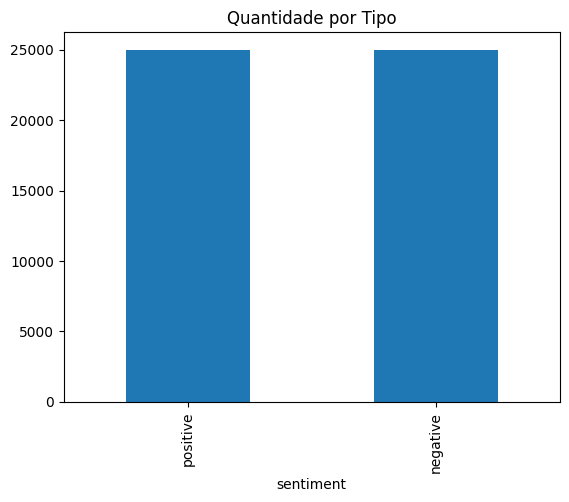

In [4]:
df["sentiment"].value_counts().plot.bar(title='Quantidade por Tipo',rot=90)

In [5]:
!pip install nltk
import nltk
nltk.download('stopwords')
nltk.download('punkt_tab')

[nltk_data] Downloading package stopwords to /root/nltk_data...
[nltk_data]   Unzipping corpora/stopwords.zip.
[nltk_data] Downloading package punkt_tab to /root/nltk_data...
[nltk_data]   Unzipping tokenizers/punkt_tab.zip.


True

In [6]:
exemplo = df['review'].values[0]
print(exemplo)
print(len(exemplo.split()))

One of the other reviewers has mentioned that after watching just 1 Oz episode you'll be hooked. They are right, as this is exactly what happened with me.<br /><br />The first thing that struck me about Oz was its brutality and unflinching scenes of violence, which set in right from the word GO. Trust me, this is not a show for the faint hearted or timid. This show pulls no punches with regards to drugs, sex or violence. Its is hardcore, in the classic use of the word.<br /><br />It is called OZ as that is the nickname given to the Oswald Maximum Security State Penitentary. It focuses mainly on Emerald City, an experimental section of the prison where all the cells have glass fronts and face inwards, so privacy is not high on the agenda. Em City is home to many..Aryans, Muslims, gangstas, Latinos, Christians, Italians, Irish and more....so scuffles, death stares, dodgy dealings and shady agreements are never far away.<br /><br />I would say the main appeal of the show is due to the fac

In [7]:
%%time
from nltk.tokenize import word_tokenize
import string
stopwords = nltk.corpus.stopwords.words('english')
punctuations = list(string.punctuation)
TAMANHO_MIMINO = 1
IGNORAR = ['...', 'br','.so','\'ll']
def prepara(texto):
    palavras = [i for i in word_tokenize(texto, language='english') if i not in punctuations]
    palavras = [i for i in palavras if i not in stopwords]
    palavras = [i for i in palavras if len(i) > TAMANHO_MIMINO]
    palavras = [i.lower() for i in palavras if i not in IGNORAR]
    return palavras

CPU times: user 2.49 ms, sys: 0 ns, total: 2.49 ms
Wall time: 10.3 ms


In [8]:
%%time
df['review2'] = df['review'].apply(prepara)
df['review2'] = df['review2'].apply(' '.join)

CPU times: user 1min 39s, sys: 464 ms, total: 1min 40s
Wall time: 1min 50s


In [9]:
df.head()

,review,sentiment,review2
0,One of the other reviewers has mentioned that ...,positive,one reviewers mentioned watching oz episode ho...
1,A wonderful little production. <br /><br />The...,positive,wonderful little production the filming techni...
2,I thought this was a wonderful way to spend ti...,positive,thought wonderful way spend time hot summer we...
3,Basically there's a family where a little boy ...,negative,basically 's family little boy jake thinks 's ...
4,"Petter Mattei's ""Love in the Time of Money"" is...",positive,petter mattei 's `` love time money '' visuall...


In [10]:
from sklearn.model_selection import train_test_split
X_train, X_test, y_train, y_test = train_test_split(df['review2'], df['sentiment'], test_size=0.2, random_state=0)
print('X_train shape:',X_train.shape)
print('y_train shape:',y_train.shape)
print('X_test shape:',X_test.shape)
print('y_test shape:',y_test.shape)

X_train shape: (40000,)
y_train shape: (40000,)
X_test shape: (10000,)
y_test shape: (10000,)


In [11]:
%%time
from tensorflow.keras.preprocessing.text import Tokenizer

tokenizer = Tokenizer(num_words=10000)

CPU times: user 3.57 s, sys: 479 ms, total: 4.05 s
Wall time: 4.11 s


In [12]:
# fit_on_texts varre todo o X_train e constrói o word_index completo,
# independente do limite de num_words — a restrição só vale na conversão.
tokenizer.fit_on_texts(X_train)

In [13]:
tk_X_train = tokenizer.texts_to_sequences(X_train)
tk_X_test  = tokenizer.texts_to_sequences(X_test)

In [14]:
# O +1 reserva o índice 0 para o padding, que será usado em etapas futuras.
vocab_size = len(tokenizer.word_index) + 1

In [15]:
# X_train é uma Series do pandas com índices embaralhados pelo train_test_split.
# X_train[0] busca pelo RÓTULO 0, que pode não existir ou apontar para
# uma review diferente da posição 0 da sequência numérica.
# A solução é usar .iloc[0], que acessa sempre pela POSIÇÃO real.
print("Texto original:     ", X_train.iloc[0])
print("Sequência numérica: ", tk_X_train[0])

Texto original:      that 's redeeming quality movie otherwise insults viewer 's intelligence losing track time plot reason produced. plus guy glasses ever got gig hollywood beyond
Sequência numérica:  [138, 1, 1656, 396, 3, 797, 7202, 425, 1, 1663, 2304, 1306, 14, 46, 202, 931, 836, 123, 4337, 52, 97, 8069, 267, 585]


In [16]:
# Verificação de sanidade: confirma que texto e sequência correspondem
# Útil para rodar sempre que você modificar o pipeline de dados
print("\n--- Verificação de sanidade ---")
print("Índices reais do X_train:", X_train.index[:5].tolist())
print("Primeiras palavras: ", X_train.iloc[0][:60])
print("Primeiros 10 tokens:", tk_X_train[0][:10])


--- Verificação de sanidade ---
Índices reais do X_train: [20330, 17532, 45819, 34807, 31888]
Primeiras palavras:  that 's redeeming quality movie otherwise insults viewer 's 
Primeiros 10 tokens: [138, 1, 1656, 396, 3, 797, 7202, 425, 1, 1663]


In [17]:
total_tokens_train = sum(len(seq) for seq in tk_X_train)
total_tokens_test = sum(len(seq) for seq in tk_X_test)

print(f'Total de tokens nos dados de treino: {total_tokens_train}')
print(f'Total de tokens nos dados de teste: {total_tokens_test}')

Total de tokens nos dados de treino: 4835304
Total de tokens nos dados de teste: 1216659


In [18]:
print('vocab_size:',vocab_size)

vocab_size: 98250


In [19]:
print('Max size:',max([len(i) for i in tk_X_train]))

Max size: 1170


In [20]:
%%time
from keras.preprocessing.sequence import pad_sequences
max_len = 200
tk_pad_X_train = pad_sequences(tk_X_train, padding='post', maxlen=max_len)
tk_pad_X_test = pad_sequences(tk_X_test, padding='post', maxlen=max_len)

CPU times: user 508 ms, sys: 12 ms, total: 520 ms
Wall time: 520 ms


In [21]:
from sklearn.preprocessing import LabelBinarizer
lb = LabelBinarizer()
ohe_y_train = lb.fit_transform(y_train)
ohe_y_test = lb.fit_transform(y_test)
print('ohe_y_train shape:',ohe_y_train.shape)
print('ohe_y_test shape:',ohe_y_test.shape)

ohe_y_train shape: (40000, 1)
ohe_y_test shape: (10000, 1)


In [22]:
from google.colab import drive
import os

# Monta o Google Drive
drive.mount('/content/drive')

# Defina o caminho do arquivo txt dentro do seu Drive
# Exemplo: '/content/drive/MyDrive/pasta/arquivo.txt'
file_path_drive = '/content/drive/MyDrive/Colab Notebooks/Pós-graduação | IA e Ciência de Dados/Processamento de Linguagem Natural/Unidade 03/GloVe/glove.6B.50d.txt'

if os.path.exists(file_path_drive):
    with open(file_path_drive, 'r', encoding='utf-8') as f:
        conteudo = f.read()
    print("Arquivo lido com sucesso!")
    print(f"Prévia do conteúdo: {conteudo[:100]}...")
else:
    print(f"Erro: O arquivo no caminho {file_path_drive} não foi encontrado.")

Mounted at /content/drive
Arquivo lido com sucesso!
Prévia do conteúdo: the 0.418 0.24968 -0.41242 0.1217 0.34527 -0.044457 -0.49688 -0.17862 -0.00066023 -0.6566 0.27843 -0...


In [23]:
%%bash -s "$file_path_drive"
# Usamos a flag -s para passar a variável do Python para o Bash
head -n 1 "$1" | cut -c-100

the 0.418 0.24968 -0.41242 0.1217 0.34527 -0.044457 -0.49688 -0.17862 -0.00066023 -0.6566 0.27843 -0


In [24]:
%%time
import numpy as np
def create_embedding(path, word_index, embedding_dim):
    vocab_size = len(word_index) + 1
    embedding = np.zeros((vocab_size, embedding_dim))
    with open(path) as f:
        for line in f:
            w, *vector = line.split()
            if w in word_index:
                idx = word_index[w]
                embedding[idx] = np.array(vector, dtype=np.float32)[:embedding_dim]
    return embedding

CPU times: user 8 µs, sys: 0 ns, total: 8 µs
Wall time: 12.9 µs


In [25]:
%%time
embedding_dim = 50
embedding_matrix = create_embedding(file_path_drive, tokenizer.word_index, embedding_dim)
print(embedding_matrix.shape)

(98250, 50)
CPU times: user 2.76 s, sys: 90.9 ms, total: 2.85 s
Wall time: 2.87 s


In [26]:
from keras.models import Sequential
from keras.layers import Embedding, Flatten, Dense, Dropout, LSTM
from keras.optimizers import Adam, Nadam

In [27]:
NB_EPOCH = 3
BATCH_SIZE = 256
VERBOSE = 1
OPTIMIZER = Adam()

In [28]:
model = Sequential()
model.add(Embedding(vocab_size, 128, input_length=max_len))
model.add(LSTM(128))
model.add(Dense(1, activation='sigmoid'))
model.compile(optimizer=OPTIMIZER, loss='binary_crossentropy', metrics=['accuracy'])
model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/core/embedding.py:100: UserWarning: Argument `input_length` is deprecated. Just remove it.
  warnings.warn(


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ embedding (Embedding)           │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ lstm (LSTM)                     │ ?                      │   0 (unbuilt) │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ ?                      │   0 (unbuilt) │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 0 (0.00 B)

 Trainable params: 0 (0.00 B)

 Non-trainable params: 0 (0.00 B)

In [29]:
%%time
history = model.fit(tk_pad_X_train, ohe_y_train,
                    epochs=NB_EPOCH,
                    verbose=1,
                    validation_data=(tk_pad_X_test, ohe_y_test),
                    batch_size=BATCH_SIZE)

Epoch 1/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 258s 2s/step - accuracy: 0.5112 - loss: 0.7177 - val_accuracy: 0.5036 - val_loss: 0.6938
Epoch 2/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 253s 2s/step - accuracy: 0.5335 - loss: 0.6807 - val_accuracy: 0.5356 - val_loss: 0.6659
Epoch 3/3
157/157 ━━━━━━━━━━━━━━━━━━━━ 251s 2s/step - accuracy: 0.5592 - loss: 0.6476 - val_accuracy: 0.5557 - val_loss: 0.6521
CPU times: user 18min 15s, sys: 1min 31s, total: 19min 46s
Wall time: 12min 42s


In [30]:
loss, accuracy = model.evaluate(tk_pad_X_test, ohe_y_test, verbose=False)
print("Acurácia do Teste:  {:.4f}".format(accuracy))

Acurácia do Teste:  0.5557


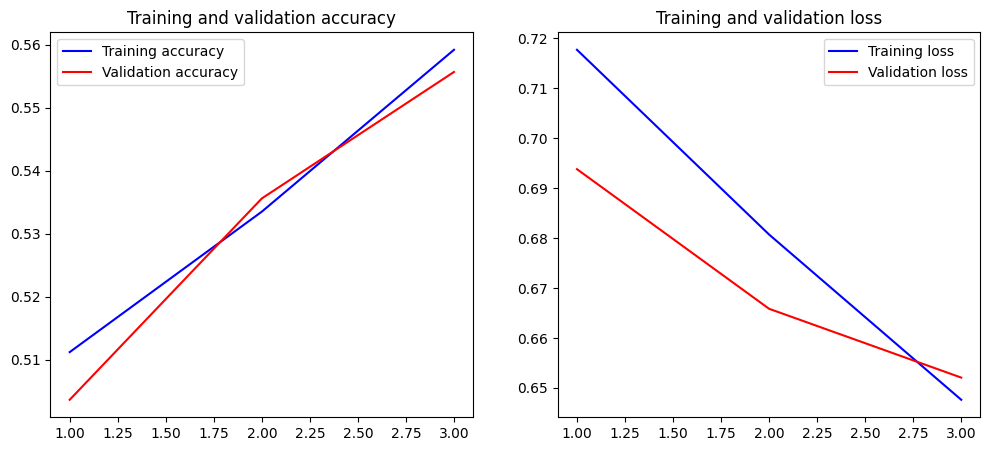

In [32]:
import matplotlib.pyplot as plt
def plot_history(history):
    acc = history.history['accuracy']
    val_acc = history.history['val_accuracy']
    loss = history.history['loss']
    val_loss = history.history['val_loss']
    x = range(1, len(acc) + 1)

    plt.figure(figsize=(12, 5))
    plt.subplot(1, 2, 1)
    plt.plot(x, acc, 'b', label='Training accuracy')
    plt.plot(x, val_acc, 'r', label='Validation accuracy')
    plt.title('Training and validation accuracy')
    plt.legend()
    plt.subplot(1, 2, 2)
    plt.plot(x, loss, 'b', label='Training loss')
    plt.plot(x, val_loss, 'r', label='Validation loss')
    plt.title('Training and validation loss')
    plt.legend()
plot_history(history)